# Heart Murmur Classification Using Deep Learning

### *Comparative Study of CNN and LSTM Models on the CirCor DigiScope Dataset*

**Machine Learning II · 2026/2027**  
**Work developed by** Afonso Santos e Rafael Santos

## 1. Introdução

A auscultação cardíaca permite identificar alterações nos sons produzidos pelo coração. Entre essas alterações encontram-se os sopros cardíacos (*heart murmurs*), que podem ser detetados através da análise de gravações fonocardiográficas. Neste projeto, estudamos a classificação automática de pacientes nas categorias **Present**, **Unknown** e **Absent**, recorrendo a redes neuronais profundas.

O conjunto de dados CirCor DigiScope contém várias gravações por paciente, obtidas em diferentes posições de auscultação. A previsão final é realizada **ao nível do paciente**, combinando a informação dos seus registos. Serão desenvolvidos e comparados dois classificadores: uma rede neuronal convolucional (CNN) e uma rede neuronal recorrente baseada em LSTM. Nesta primeira fase, caracterizamos os dados e estabelecemos as condições para o seu pré-processamento e avaliação.

## 2. Dados e exploração inicial

### Bibliotecas e configuração

Utilizamos `pandas` e `numpy` para manipulação de dados, `soundfile` e `librosa` para processamento de áudio, e `matplotlib` para visualização. Os modelos serão implementados com TensorFlow/Keras. As funções auxiliares de análise e visualização encontram-se em `utils.py`, enquanto as decisões metodológicas e os resultados permanecem no notebook.

In [14]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from IPython.display import Audio, display

from utils import (
    CLASSES, weighted_accuracy, plot_class_distribution,
    audio_headers, plot_duration_distribution,
    plot_recording_coverage, choose_examples,
    read_audio_excerpt, plot_signal_and_mel,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': .2})

print('TensorFlow:', tf.__version__)
print('Diretório atual:', Path.cwd())

TensorFlow: 2.21.0
Diretório atual: c:\Users\Afonso Santos\Desktop\3 ano\ac2\projeto


### Dataset CirCor DigiScope

O conjunto público contém 942 pacientes e 3163 gravações. O ficheiro `training_data.csv` reúne os metadados dos pacientes e a variável `Murmur`, utilizada como alvo da classificação. As gravações são disponibilizadas em formato WAV, identificadas pelo paciente e pela posição de auscultação.

Começamos por verificar a estrutura dos ficheiros e a correspondência entre os registos e os respetivos áudios.

In [15]:
DATA_DIR = Path('dataset')
AUDIO_DIR = DATA_DIR / 'training_data'
CSV_PATH = DATA_DIR / 'training_data.csv'

for path in (DATA_DIR, AUDIO_DIR, CSV_PATH):
    if not path.exists():
        raise FileNotFoundError(f'Ficheiro/pasta não encontrado: {path.resolve()}')

wav_files = sorted(AUDIO_DIR.glob('*.wav'))
print('Gravações encontradas:', len(wav_files))
print('Ficheiros principais:', ', '.join(sorted(p.name for p in DATA_DIR.iterdir())))

Gravações encontradas: 3163
Ficheiros principais: LICENSE.txt, RECORDS, SHA256SUMS.txt, index.html, training_data, training_data.csv


In [16]:
raw_metadata = pd.read_csv(CSV_PATH, dtype=str)
raw_metadata.columns = raw_metadata.columns.str.strip()
id_columns = [col for col in raw_metadata.columns
              if col.lower().replace('_', ' ').strip() == 'patient id']

if len(id_columns) != 1 or 'Murmur' not in raw_metadata.columns:
    raise ValueError('Não foi possível localizar Patient ID e Murmur no CSV.')

patients = raw_metadata[[id_columns[0], 'Murmur']].copy()
patients.columns = ['patient_id', 'murmur']
patients = patients.apply(lambda col: col.str.strip())
patients = patients.sort_values('patient_id').reset_index(drop=True)

assert patients['patient_id'].notna().all() and patients['patient_id'].is_unique
assert patients['murmur'].isin(CLASSES).all()
print('Pacientes:', len(patients), '| Colunas originais:', len(raw_metadata.columns))
display(patients.head(10))

Pacientes: 942 | Colunas originais: 23


,patient_id,murmur
0,13918,Present
1,14241,Present
2,14998,Absent
3,23625,Absent
4,24160,Absent
5,2530,Absent
6,29045,Present
7,29378,Unknown
8,31737,Absent
9,33151,Present


### Distribuição dos diagnósticos

A frequência das classes é calculada por paciente, e não por gravação. Como o número de registos varia entre pacientes, esta distinção evita que pessoas com mais gravações influenciem artificialmente a distribuição dos diagnósticos.

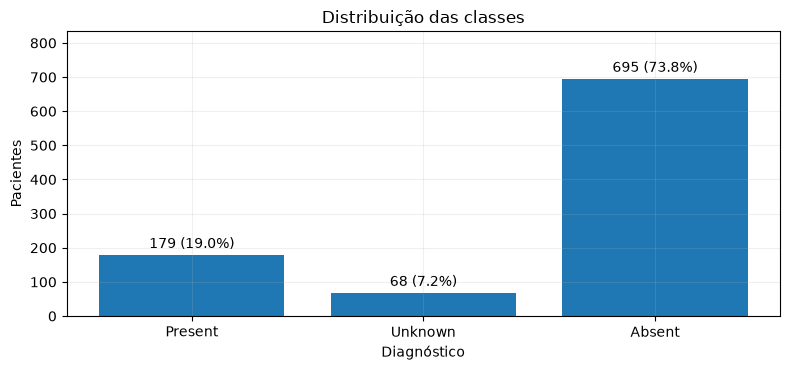

In [17]:
plot_class_distribution(patients)

> A distribuição dos diagnósticos evidencia um desequilíbrio significativo entre as classes. Dos 942 pacientes, 695 pertencem à classe *Absent* (73,8%), 179 à classe *Present* (19,0%) e apenas 68 à classe *Unknown* (7,2%).
> Esta predominância poderá levar os modelos a favorecer a classe maioritária durante o treino, sendo necessário avaliar estratégias para lidar com o desequilíbrio e assegurar um desempenho adequado nas três classes.

### Inventário das gravações

A partir dos nomes dos ficheiros construímos um índice que associa cada áudio ao paciente e à posição de auscultação. O diagnóstico é acrescentado para organizar os dados e permitir a avaliação, mas não será utilizado como característica de entrada dos modelos.

In [18]:
recordings = pd.DataFrame({
    'path': wav_files,
    'filename': [p.name for p in wav_files],
    'patient_id': [p.stem.split('_', 1)[0] for p in wav_files],
    'location': [p.stem.split('_', 1)[1] if '_' in p.stem else 'N/A'
                 for p in wav_files],
})

assert set(recordings['patient_id']) == set(patients['patient_id']), 'Pacientes inconsistentes.'
assert len(patients) == 942 and len(recordings) == 3163, 'Contagens diferentes das esperadas.'

recordings = recordings.merge(patients, on='patient_id', how='left', validate='many_to_one')
print('Pacientes com gravações:', recordings['patient_id'].nunique())
print('Gravações:', len(recordings))
display(recordings[['filename', 'patient_id', 'location', 'murmur']].head(10))

Pacientes com gravações: 942
Gravações: 3163


,filename,patient_id,location,murmur
0,13918_AV.wav,13918,AV,Present
1,13918_MV.wav,13918,MV,Present
2,13918_PV.wav,13918,PV,Present
3,13918_TV.wav,13918,TV,Present
4,14241_AV.wav,14241,AV,Present
5,14241_MV.wav,14241,MV,Present
6,14241_PV.wav,14241,PV,Present
7,14241_TV.wav,14241,TV,Present
8,14998_AV.wav,14998,AV,Absent
9,14998_MV.wav,14998,MV,Absent


## 3. Partição dos dados por paciente

Definimos três conjuntos independentes: **70% para treino, 15% para validação e 15% para teste**. A divisão é estratificada pelo diagnóstico e realizada antes de criar janelas de áudio ou ajustar transformações estatísticas.

Cada paciente pertence a uma única partição, incluindo todas as suas gravações. O conjunto de validação será utilizado na seleção dos modelos e dos parâmetros; o teste ficará reservado para a avaliação final.

In [19]:
development_patients, test_patients = train_test_split(
    patients, test_size=0.15, random_state=SEED, stratify=patients['murmur'])
train_patients, val_patients = train_test_split(
    development_patients, test_size=0.15 / 0.85, random_state=SEED,
    stratify=development_patients['murmur'])

parts = {'train': train_patients, 'validation': val_patients, 'test': test_patients}
patient_ids = {name: set(data['patient_id']) for name, data in parts.items()}
assert all(patient_ids[a].isdisjoint(patient_ids[b]) for a, b in
           [('train', 'validation'), ('train', 'test'), ('validation', 'test')])

patient_split = pd.concat([data.assign(split=name) for name, data in parts.items()])
patient_split = patient_split.sort_values('patient_id').reset_index(drop=True)
recordings = recordings.merge(patient_split[['patient_id', 'split']],
                              on='patient_id', how='left', validate='many_to_one')
assert recordings['split'].notna().all()

RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(exist_ok=True)
patient_split[['patient_id', 'split']].to_csv(RESULTS_DIR / 'patient_split.csv', index=False)

counts = pd.crosstab(patient_split['split'], patient_split['murmur']).reindex(
    index=['train', 'validation', 'test'], columns=CLASSES, fill_value=0)
counts['Total'] = counts.sum(axis=1)
print('Pacientes por partição e diagnóstico:')
display(counts)
print('Proporções de cada diagnóstico por partição (%):')
display((100 * counts[list(CLASSES)].div(counts['Total'], axis=0)).round(1))
print('Divisão guardada em results/patient_split.csv')

Pacientes por partição e diagnóstico:


murmur,Present,Unknown,Absent,Total
split,,,,
train,125,48,485,658
validation,27,10,105,142
test,27,10,105,142


Proporções de cada diagnóstico por partição (%):


murmur,Present,Unknown,Absent
split,,,
train,19.0,7.3,73.7
validation,19.0,7.0,73.9
test,19.0,7.0,73.9


Divisão guardada em results/patient_split.csv


> A partição resultou em 658 pacientes para treino, 142 para validação e 142 para teste, preservando aproximadamente as proporções originais das três classes. A separação por paciente garante que gravações pertencentes ao mesmo indivíduo não sejam distribuídas por diferentes conjuntos, evitando uma avaliação artificialmente otimista. O conjunto de teste será mantido independente de todas as decisões de desenvolvimento, ficando reservado para a avaliação final dos modelos.

## 4. Caracterização acústica

As frequências de amostragem, os canais e as durações dos sinais condicionam as escolhas de pré-processamento. A partir deste ponto, exploramos **apenas os áudios do conjunto de treino**, preservando a validação e o teste para as suas finalidades próprias.

A leitura dos cabeçalhos permite caracterizar todas as gravações de treino sem carregar os sinais completos para memória.

Gravações de treino analisadas: 2225
Frequências de amostragem (Hz):


,Gravações
sample_rate,
4000,2225


Canais de áudio:


,Gravações
channels,
1,2225


Estatísticas das durações (s):


,Segundos
count,2225.00
mean,22.87
std,7.36
min,5.15
10%,12.79
25%,18.85
50%,21.49
75%,29.39
90%,31.09
max,64.51


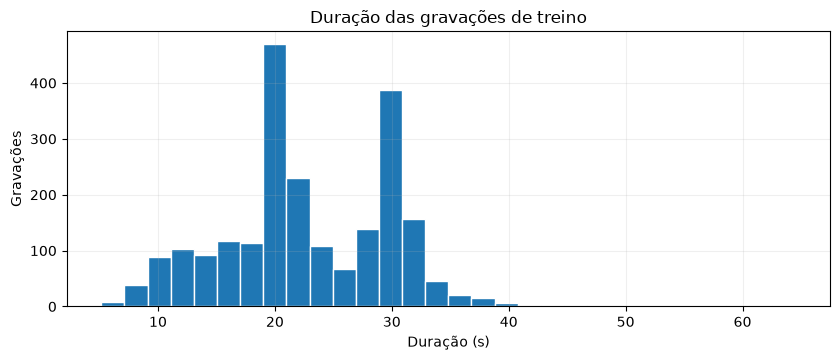

In [20]:
train_recordings = recordings.loc[recordings['split'] == 'train'].copy().reset_index(drop=True)
train_audio_stats = train_recordings.merge(
    audio_headers(train_recordings['path']), on='filename', validate='one_to_one')

print('Gravações de treino analisadas:', len(train_audio_stats))
print('Frequências de amostragem (Hz):')
display(train_audio_stats['sample_rate'].value_counts().sort_index().rename('Gravações').to_frame())
print('Canais de áudio:')
display(train_audio_stats['channels'].value_counts().sort_index().rename('Gravações').to_frame())
print('Estatísticas das durações (s):')
display(train_audio_stats['duration_s'].describe(
    percentiles=[.1, .25, .5, .75, .9]).round(2).to_frame(name='Segundos'))
plot_duration_distribution(train_audio_stats)

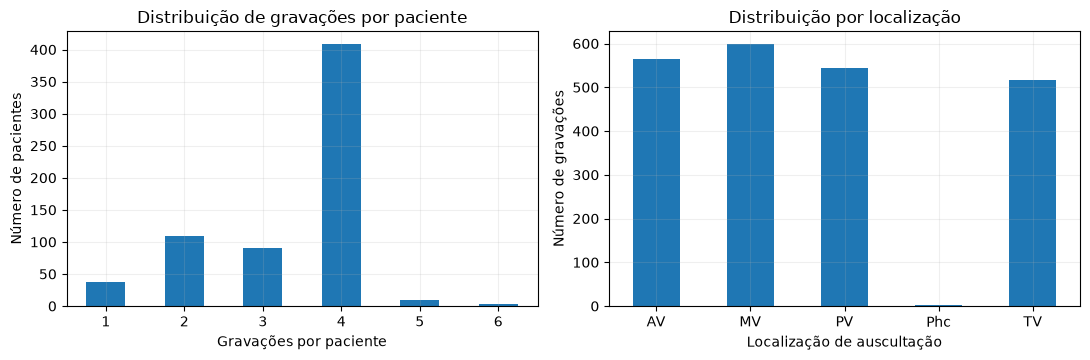

In [21]:
plot_recording_coverage(train_recordings)

> As gravações analisadas apresentam uma frequência de amostragem uniforme de 4000 Hz e um único canal, não sendo necessária uma conversão inicial para uniformizar estas características.

> Em contrapartida, observa-se uma variabilidade considerável na duração dos sinais, com uma mediana de aproximadamente 21,5 segundos. Verifica-se também que o número de gravações por paciente não é constante, embora a maioria disponha de quatro registos obtidos em diferentes posições de auscultação.

> Estas características justificam a utilização de uma estratégia de segmentação temporal que preserve a informação ao longo das gravações, bem como a posterior combinação das previsões numa única classificação por paciente.

### Sinais cardíacos e representação tempo-frequência

A forma de onda mostra a variação da amplitude ao longo do tempo; o mel-espectrograma representa a energia distribuída pelas bandas de frequência. A escala logarítmica facilita a visualização de diferenças de intensidade.

Para ilustrar as duas representações, selecionamos **uma gravação por classe, de pacientes distintos**, exclusivamente do treino. Os excertos de oito segundos e os parâmetros de extração utilizados nesta visualização são exploratórios: ainda não correspondem à configuração final dos modelos. Um exemplo isolado não é representativo de todos os pacientes da mesma classe.

,filename,patient_id,location,murmur
0,49691_TV.wav,49691,TV,Present
1,84919_PV.wav,84919,PV,Unknown
2,59536_MV.wav,59536,MV,Absent


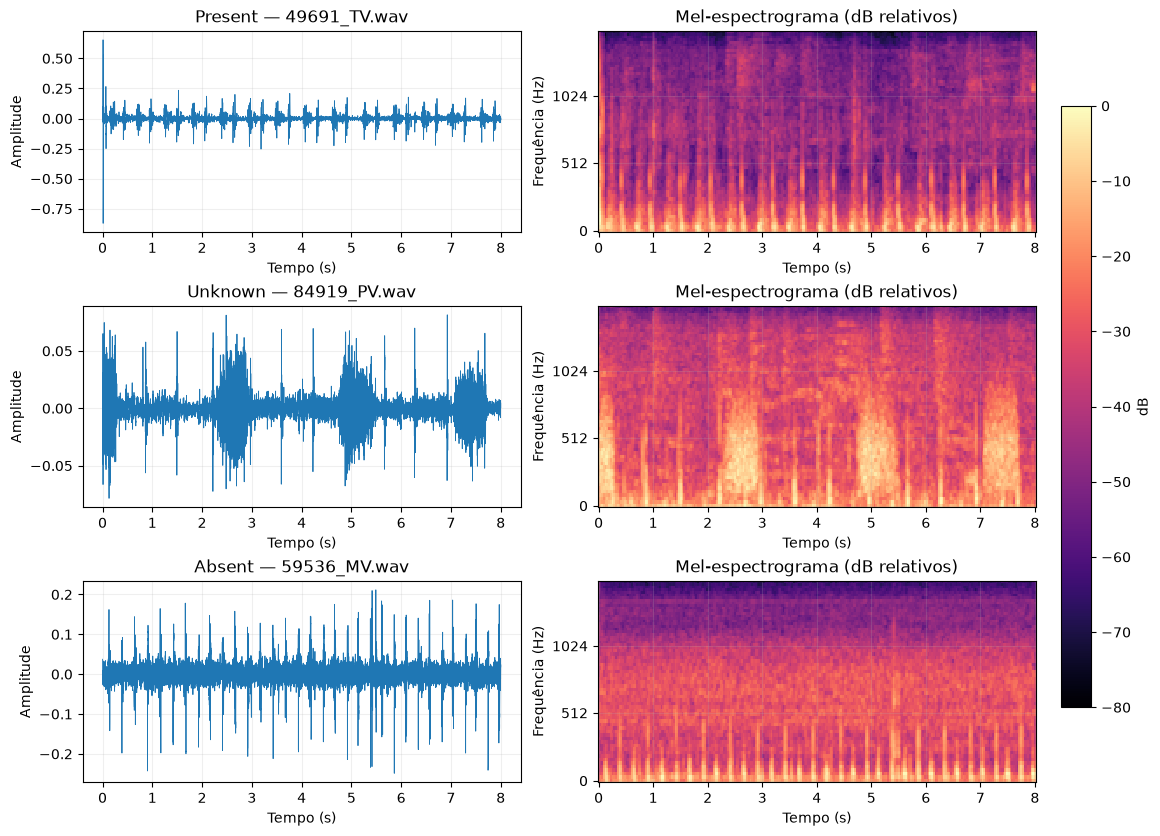

In [22]:
N_FFT, HOP_LENGTH, N_MELS = 512, 128, 64
examples = choose_examples(train_recordings, n_per_class=1, seed=SEED)
display(examples[['filename', 'patient_id', 'location', 'murmur']])
plot_signal_and_mel(examples, seconds=8, n_fft=N_FFT,
                    hop_length=HOP_LENGTH, n_mels=N_MELS)

> A análise das formas de onda permite identificar padrões temporais repetitivos associados à atividade cardíaca, enquanto os mel-espectrogramas evidenciam a distribuição da energia pelas diferentes frequências ao longo do tempo.

> Observam-se diferenças na amplitude e na organização temporal e espectral dos sinais apresentados. Contudo, estas observações têm caráter ilustrativo, uma vez que os exemplos representam apenas gravações individuais de pacientes com diagnósticos distintos.



### Audição de um excerto

A escuta complementa a observação da forma de onda e do espectrograma, sem constituir uma avaliação clínica do sinal.

In [23]:
example_row = examples.iloc[0]
signal, sr = read_audio_excerpt(example_row['path'], seconds=8)
print(example_row['filename'], '| Diagnóstico do paciente:', example_row['murmur'])
display(Audio(signal, rate=sr))

49691_TV.wav | Diagnóstico do paciente: Present


## 5. Avaliação e referência inicial

A métrica principal será a **weighted accuracy por paciente**, com pesos de 5 para `Present`, 3 para `Unknown` e 1 para `Absent`. Após o treino, as previsões das gravações de um mesmo paciente serão agregadas numa única classificação, sobre a qual a métrica será calculada.

Como referência inicial, comparamos classificadores constantes que atribuem sempre a mesma classe aos pacientes de **treino**. Esta comparação evidencia a diferença entre accuracy convencional e weighted accuracy num conjunto desequilibrado, sem recorrer à validação ou ao teste.

In [24]:
assert np.isclose(weighted_accuracy(['Present', 'Unknown', 'Absent'],
                                     ['Absent', 'Unknown', 'Absent']), 4 / 9)
assert np.isclose(weighted_accuracy(CLASSES, CLASSES), 1.0)

train_labels = train_patients['murmur'].to_numpy()
baselines = []
for label in CLASSES:
    predictions = np.repeat(label, len(train_labels))
    baselines.append({
        'Previsão constante': label,
        'Accuracy': accuracy_score(train_labels, predictions),
        'Weighted accuracy': weighted_accuracy(train_labels, predictions),
    })
display(pd.DataFrame(baselines).round(3))

,Previsão constante,Accuracy,Weighted accuracy
0,Present,0.190,0.498
1,Unknown,0.073,0.115
2,Absent,0.737,0.387


> Os classificadores constantes demonstram que a accuracy convencional pode ser pouco representativa do desempenho neste problema. A previsão sistemática da classe *Absent* permite obter uma accuracy de aproximadamente 73,7%, mas uma weighted accuracy de apenas 38,7%.

> Por outro lado, a previsão constante de *Present* atinge uma weighted accuracy de aproximadamente 49,8%, apesar de apresentar uma accuracy convencional bastante inferior. Esta diferença reflete a maior importância atribuída à classificação correta dos pacientes *Present* e *Unknown*.

> Estes resultados constituem uma referência inicial para a avaliação dos modelos, destacando a necessidade de analisar o desempenho nas diferentes classes e não apenas a proporção global de previsões corretas.

### Preparação da fase seguinte

A distribuição dos diagnósticos, a cobertura das posições de auscultação e a variabilidade das durações permitem fundamentar a seleção da duração das janelas e dos parâmetros das características acústicas.

Na próxima fase, definiremos o pré-processamento e a construção dos exemplos de treino para a **CNN 2D** e a **LSTM**, mantendo a mesma divisão por paciente e ajustando quaisquer estatísticas apenas com dados de treino. As decisões concretas serão registadas após a análise dos resultados obtidos.